# CA2: Statistical technique for Data Analysis

## Project Title: Statistical Analysis of Depression Prevalence Among Older Adults Across Countries: A Global Comparative Study (1990–2023)

### Lecturer(s): Taufique Ahmed



Global Burden of Disease Collaborative Network. Global Burden of Disease Study 2023 (GBD 2023). Seattle, United States: Institute for Health Metrics and Evaluation (IHME), 2025. Available from [IHME, Global Burden of Disease (2025)](https://vizhub.healthdata.org/gbd-results/)

## Introduction

## Dataset Inspection & Preparation

### Import necessary libraries and Load Dataset

In [ ]:
# Import libraries used across the notebook.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Load dataset
df = pd.read_csv("IHME-GBD_2023_DATA-Global-1.csv")

### Dataset Inspection

In [ ]:
# Check dataset structure
print("Demographic Rows:", df.shape[0])
print("Demographic Columns:", df.shape[1])

display(df.head())
df.info()

Demographic Rows: 97104
Demographic Columns: 18


,population_group_id,population_group_name,measure_id,measure_name,location_id,location_name,sex_id,sex_name,age_id,age_name,cause_id,cause_name,metric_id,metric_name,year,val,upper,lower
0,1,All Population,5,Prevalence,38,Mongolia,1,Male,17,60-64 years,567,Depressive disorders,3,Rate,1990,3110.875334,4082.632139,2318.468600
1,1,All Population,5,Prevalence,38,Mongolia,2,Female,17,60-64 years,567,Depressive disorders,3,Rate,1990,4683.797762,5983.796224,3585.181457
2,1,All Population,5,Prevalence,38,Mongolia,1,Male,18,65-69 years,567,Depressive disorders,3,Rate,1990,3130.898877,4001.377857,2376.084179
3,1,All Population,5,Prevalence,38,Mongolia,2,Female,18,65-69 years,567,Depressive disorders,3,Rate,1990,4720.660139,5953.136411,3608.595159
4,1,All Population,5,Prevalence,38,Mongolia,1,Male,19,70-74 years,567,Depressive disorders,3,Rate,1990,3151.444214,3934.790463,2415.426351


<class 'pandas.DataFrame'>
RangeIndex: 97104 entries, 0 to 97103
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   population_group_id    97104 non-null  int64  
 1   population_group_name  97104 non-null  str    
 2   measure_id             97104 non-null  int64  
 3   measure_name           97104 non-null  str    
 4   location_id            97104 non-null  int64  
 5   location_name          97104 non-null  str    
 6   sex_id                 97104 non-null  int64  
 7   sex_name               97104 non-null  str    
 8   age_id                 97104 non-null  int64  
 9   age_name               97104 non-null  str    
 10  cause_id               97104 non-null  int64  
 11  cause_name             97104 non-null  str    
 12  metric_id              97104 non-null  int64  
 13  metric_name            97104 non-null  str    
 14  year                   97104 non-null  int64  
 15  val          

In [ ]:
# Check column names
print("\nColumn names:") 
display(df.columns.tolist())


Column names:


['population_group_id',
 'population_group_name',
 'measure_id',
 'measure_name',
 'location_id',
 'location_name',
 'sex_id',
 'sex_name',
 'age_id',
 'age_name',
 'cause_id',
 'cause_name',
 'metric_id',
 'metric_name',
 'year',
 'val',
 'upper',
 'lower']

In [ ]:
# Review descriptive statistics for the dataset.
print("Descriptive statistics:")
print(df.describe())

Descriptive statistics:
       population_group_id  measure_id   location_id        sex_id  \
count              97104.0     97104.0  97104.000000  97104.000000   
mean                   1.0         5.0    136.299020      1.500000   
std                    0.0         0.0     97.922111      0.500003   
min                    1.0         5.0      6.000000      1.000000   
25%                    1.0         5.0     62.750000      1.000000   
50%                    1.0         5.0    122.500000      1.500000   
75%                    1.0         5.0    182.250000      2.000000   
max                    1.0         5.0    522.000000      2.000000   

             age_id  cause_id  metric_id          year           val  \
count  97104.000000   97104.0    97104.0  97104.000000  97104.000000   
mean      23.857143     567.0        3.0   2006.500000   4351.748473   
std        6.266236       0.0        0.0      9.810759   1238.183383   
min       17.000000     567.0        3.0   1990.000000   

In [ ]:
# Review descriptive statistics for selected 'val' columns
descriptive_stats = df["val"].describe()
print(descriptive_stats)

count    97104.000000
mean      4351.748473
std       1238.183383
min       1466.927519
25%       3480.409446
50%       4174.813049
75%       5100.006659
max      11692.639516
Name: val, dtype: float64


In [ ]:
# Review all descriptive statistics
overall_stats = pd.DataFrame({
    "Mean": [df["val"].mean()],
    "Median": [df["val"].median()],
    "SD": [df["val"].std()],
    "Minimum": [df["val"].min()],
    "Maximum": [df["val"].max()],
    "Q1": [df["val"].quantile(0.25)],
    "Q2": [df["val"].quantile(0.50)],
    "Q3": [df["val"].quantile(0.75)],
    "IQR": [df["val"].quantile(0.75) - df["val"].quantile(0.25)]})
overall_stats.round(2)

,Mean,Median,SD,Minimum,Maximum,Q1,Q2,Q3,IQR
0,4351.75,4174.81,1238.18,1466.93,11692.64,3480.41,4174.81,5100.01,1619.6


In [ ]:
# Review descriptive statistics by genders
sex_stats = df.groupby("sex_name")["val"].agg(["count", "mean", "median", "std", "min", "max"])
sex_stats.round(2).T

sex_name,Female,Male
count,48552.00,48552.00
mean,5104.18,3599.32
median,5018.29,3546.97
std,1110.95,836.48
min,1787.99,1466.93
max,11692.64,9228.06


In [ ]:
# Review descriptive statistics by country
country_stats = df.groupby("location_name")["val"].agg(["count", "mean", "median", "std", "min", "max"])
country_stats.round(2).T

location_name,Afghanistan,Albania,Algeria,American Samoa,Andorra,Angola,Antigua and Barbuda,Argentina,Armenia,Australia,...,United States Virgin Islands,United States of America,Uruguay,Uzbekistan,Vanuatu,Venezuela (Bolivarian Republic of),Viet Nam,Yemen,Zambia,Zimbabwe
count,476.00,476.00,476.00,476.00,476.00,476.00,476.00,476.00,476.00,476.00,...,476.00,476.00,476.00,476.00,476.00,476.00,476.00,476.00,476.00,476.00
mean,5530.04,3786.81,5306.83,3992.52,3824.87,6427.88,4285.27,3412.49,4758.82,3640.14,...,3602.38,3698.34,3171.36,4590.60,3915.62,4396.76,3362.68,5310.59,4540.00,4207.44
median,5449.58,3722.91,5275.93,3931.83,3944.09,6700.87,4563.96,3587.90,4879.01,3566.14,...,3813.01,3755.63,3194.93,4615.89,3833.66,4659.53,3381.01,5191.56,4740.92,4371.42
std,823.12,778.01,714.50,396.52,1015.21,1233.68,1014.95,898.70,1069.02,325.60,...,661.30,852.84,1137.47,976.36,383.39,962.29,776.06,879.25,723.70,642.04
min,4366.79,2564.66,3907.87,3316.58,2654.55,4891.75,3003.29,2335.91,3133.11,3143.63,...,2739.36,2629.61,1947.66,3133.26,3316.15,3201.58,2391.55,3776.87,3489.24,3250.13
max,8121.28,5529.49,7322.90,5023.41,6245.60,9493.66,6684.73,5931.88,7442.74,4567.48,...,5114.18,6284.07,5829.44,6541.75,4956.52,6383.38,4852.44,7900.66,6491.22,5944.27


In [ ]:
# Count missing values
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
population_group_id      0
population_group_name    0
measure_id               0
measure_name             0
location_id              0
location_name            0
sex_id                   0
sex_name                 0
age_id                   0
age_name                 0
cause_id                 0
cause_name               0
metric_id                0
metric_name              0
year                     0
val                      0
upper                    0
lower                    0
dtype: int64


In [ ]:
# Check duplicate
df.duplicated().sum()

np.int64(0)

### Region Mapping

In [ ]:
# Import country_converter
%pip install country_converter

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import country_converter as coco
cc = coco.CountryConverter()

In [ ]:
# Create region mapping
locations = df["location_name"].unique()

region_mapping = pd.DataFrame({
    "location_name": locations,
    "region": cc.convert(
        names=locations,
        to="UNregion",
        not_found=None
    )
})

# Create region column directly using map()
region_lookup = region_mapping.set_index(
    "location_name"
)["region"]

df["region"] = df["location_name"].map(region_lookup)

In [ ]:
df.columns.tolist()

['population_group_id',
 'population_group_name',
 'measure_id',
 'measure_name',
 'location_id',
 'location_name',
 'sex_id',
 'sex_name',
 'age_id',
 'age_name',
 'cause_id',
 'cause_name',
 'metric_id',
 'metric_name',
 'year',
 'val',
 'upper',
 'lower',
 'region']

In [ ]:
# Check columns
print("Region column exists:", "region" in df.columns)

# Display UN subregions
region_summary = (df.groupby("region")["location_name"].nunique().sort_values(ascending=False))
display(region_summary)

Region column exists: True


region
Eastern Africa               18
Western Asia                 18
Western Africa               16
Caribbean                    15
Southern Europe              14
South America                12
South-eastern Asia           11
Eastern Europe               10
Northern Europe              10
Southern Asia                 9
Middle Africa                 9
Polynesia                     8
Central America               8
Western Europe                8
Northern Africa               6
Micronesia                    6
Eastern Asia                  6
Central Asia                  5
Southern Africa               5
Northern America              4
Melanesia                     4
Australia and New Zealand     2
Name: location_name, dtype: int64

In [ ]:
region_summary = (df.groupby("region")
    .agg(
        total_observations=("val", "count"),
        total_locations=("location_name", "nunique"),
        mean_prevalence=("val", "mean"),
        median_prevalence=("val", "median"),
        std_prevalence=("val", "std")
    ).round(2).sort_values("total_locations", ascending=False))
display(region_summary)

,total_observations,total_locations,mean_prevalence,median_prevalence,std_prevalence
region,,,,,
Eastern Africa,8568,18,4861.43,4756.29,1073.17
Western Asia,8568,18,5005.42,4873.66,1364.79
Western Africa,7616,16,4532.67,4505.66,767.34
Caribbean,7140,15,4376.74,4190.01,1098.45
Southern Europe,6664,14,3704.98,3401.39,1109.71
South America,5712,12,4006.45,3782.14,1161.16
South-eastern Asia,5236,11,3255.17,3117.90,899.95
Eastern Europe,4760,10,4298.76,4091.36,1358.15
Northern Europe,4760,10,4017.56,3787.62,1072.43


In [ ]:
#Create Geographical Region Mapping
# Map UN subregions to 5 geographical regions
subregion_to_region = {
    # Africa
    "Eastern Africa": "Africa",
    "Middle Africa": "Africa",
    "Northern Africa": "Africa",
    "Southern Africa": "Africa",
    "Western Africa": "Africa",

    # Americas
    "Caribbean": "Americas",
    "Central America": "Americas",
    "Northern America": "Americas",
    "South America": "Americas",

    # Asia
    "Central Asia": "Asia",
    "Eastern Asia": "Asia",
    "South-eastern Asia": "Asia",
    "Southern Asia": "Asia",
    "Western Asia": "Asia",

    # Europe
    "Eastern Europe": "Europe",
    "Northern Europe": "Europe",
    "Southern Europe": "Europe",
    "Western Europe": "Europe",

    # Oceania
    "Australia and New Zealand": "Oceania",
    "Melanesia": "Oceania",
    "Micronesia": "Oceania",
    "Polynesia": "Oceania"
}
# Create geographical region column
df["geographical_region"] = df["region"].map(subregion_to_region)
display(df["geographical_region"])

0           Asia
1           Asia
2           Asia
3           Asia
4           Asia
          ...   
97099    Oceania
97100    Oceania
97101    Oceania
97102    Oceania
97103    Oceania
Name: geographical_region, Length: 97104, dtype: str

In [ ]:
# Summary by Geographical Region
geographical_region_summary = (
    df.groupby("geographical_region")
    .agg(
        total_observations=("val", "count"),
        total_locations=("location_name", "nunique"),
        mean_prevalence=("val", "mean"),
        median_prevalence=("val", "median"),
        std_prevalence=("val", "std")
    ).round(2).sort_values("total_locations", ascending=False)
)
display(geographical_region_summary)

,total_observations,total_locations,mean_prevalence,median_prevalence,std_prevalence
geographical_region,,,,,
Africa,25704,54,4921.18,4763.53,1119.76
Asia,23324,49,4395.83,4188.97,1409.10
Europe,19992,42,4012.03,3765.44,1234.16
Americas,18564,39,4115.45,3917.47,1130.13
Oceania,9520,20,3880.48,3841.33,495.33


**UN Subregions → Geographical Regions**
- Africa: Eastern, Middle, Northern, Southern, Western Africa
- Americas: Caribbean, Central America, Northern America, South America
- Asia: Central, Eastern, South-eastern, Southern, Western Asia
- Europe: Eastern, Northern, Southern, Western Europe
- Oceania: Australia and New Zealand, Melanesia, Micronesia, Polynesia

In [ ]:
# Check locations without region
unmatched = (df.loc[df["region"].isna(), "location_name"].drop_duplicates().sort_values())

print("Unmatched locations:")
print(unmatched.to_list())

Unmatched locations:
[]


In [ ]:
from numpy import size


subregion_summary = (df.groupby(["geographical_region", "region","location_name"]).size().reset_index(name="observations").sort_values([ "geographical_region", "region", "location_name"]))
display(subregion_summary)

,geographical_region,region,location_name,observations
0,Africa,Eastern Africa,Burundi,476
1,Africa,Eastern Africa,Comoros,476
2,Africa,Eastern Africa,Djibouti,476
3,Africa,Eastern Africa,Eritrea,476
4,Africa,Eastern Africa,Ethiopia,476
...,...,...,...,...
199,Oceania,Polynesia,Niue,476
200,Oceania,Polynesia,Samoa,476
201,Oceania,Polynesia,Tokelau,476
202,Oceania,Polynesia,Tonga,476


### Histogram – Overall Distribution of Depression Prevalence

To examine the overall distribution of depression prevalence estimates across all geographical locations, years (1990–2023), age groups and sexes.

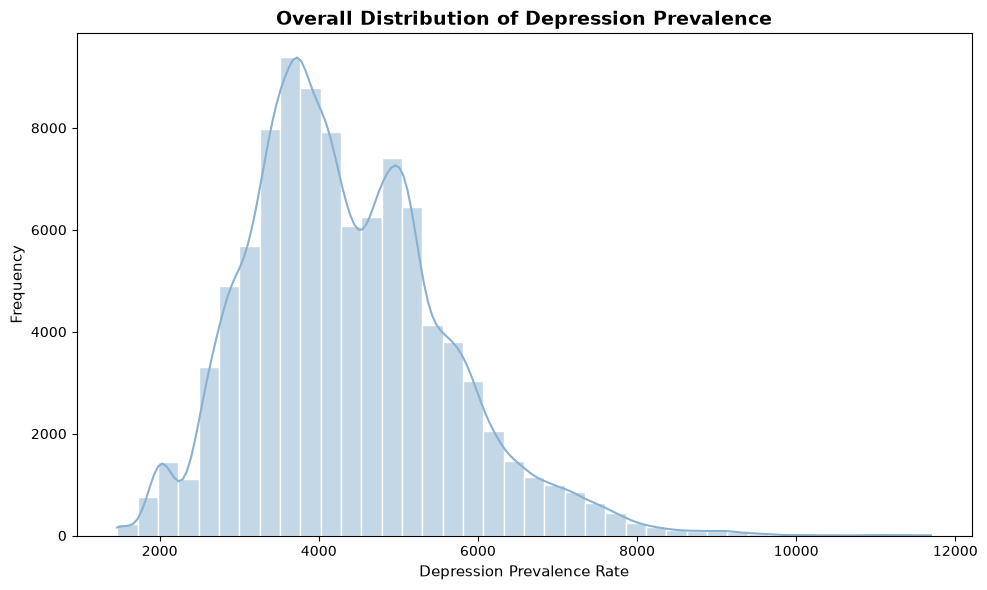

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data
hist_df = df["val"].dropna()

# Create histogram
plt.figure(figsize=(10, 6))
sns.histplot(data=hist_df, bins=40, kde=True, color="#89B1D1", edgecolor="white")

plt.title("Overall Distribution of Depression Prevalence", fontsize=14, fontweight="bold")
plt.xlabel("Depression Prevalence Rate", fontsize=11)
plt.ylabel("Frequency", fontsize=11)

plt.tight_layout()
plt.show()

In [ ]:
# Summary statistics
overall_summary = hist_df.describe()
print(hist_df.describe())
print("\nSkewness:", round(hist_df.skew(), 3))
print("\nKurtosis:", round(hist_df.kurtosis(), 3))

count    97104.000000
mean      4351.748473
std       1238.183383
min       1466.927519
25%       3480.409446
50%       4174.813049
75%       5100.006659
max      11692.639516
Name: val, dtype: float64

Skewness: 0.67

Kurtosis: 0.798


**Histogram – Overall Distribution of Depression Prevalence**

A histogram was constructed to examine the overall distribution of depression prevalence estimates across geographical locations, years, age groups and sexes from 1990 to 2023. The histogram provides an overview of the distribution's shape, concentration, spread and potential skewness. These characteristics help describe the variability of depression prevalence estimates within the dataset.

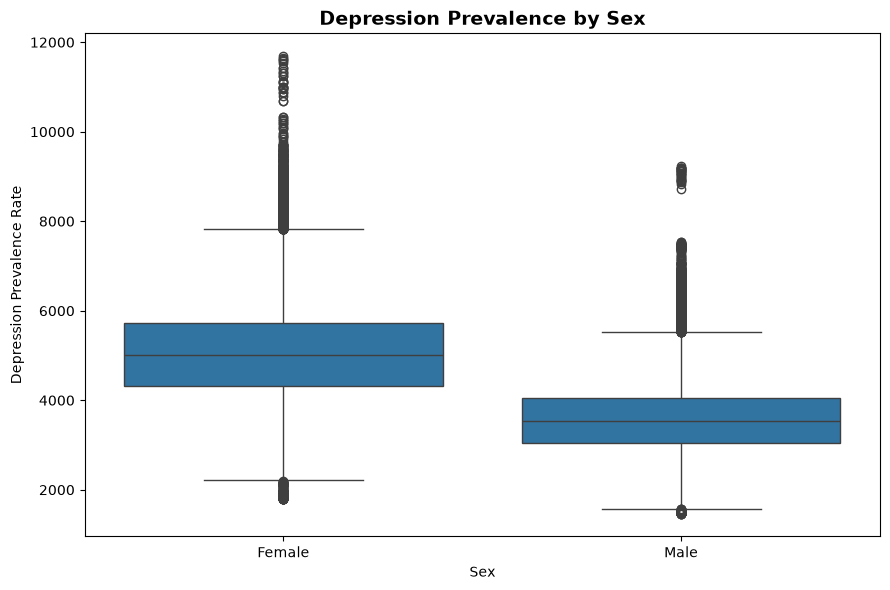

In [ ]:

sex_order = ["Female", "Male"]

sex_df = df.dropna(
    subset=["sex_name", "val"]
).copy()

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=sex_df,
    x="sex_name",
    y="val",
    order=sex_order,
    showfliers=True
)

plt.title(
    "Depression Prevalence by Sex",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Sex")
plt.ylabel("Depression Prevalence Rate")

plt.tight_layout()
plt.show()

In [ ]:
sex_summary = (
    sex_df.groupby("sex_name")["val"]
    .agg(
        observations="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
    .round(2)
)

display(sex_summary)

,observations,mean,median,std,minimum,maximum
sex_name,,,,,,
Female,48552,5104.18,5018.29,1110.95,1787.99,11692.64
Male,48552,3599.32,3546.97,836.48,1466.93,9228.06


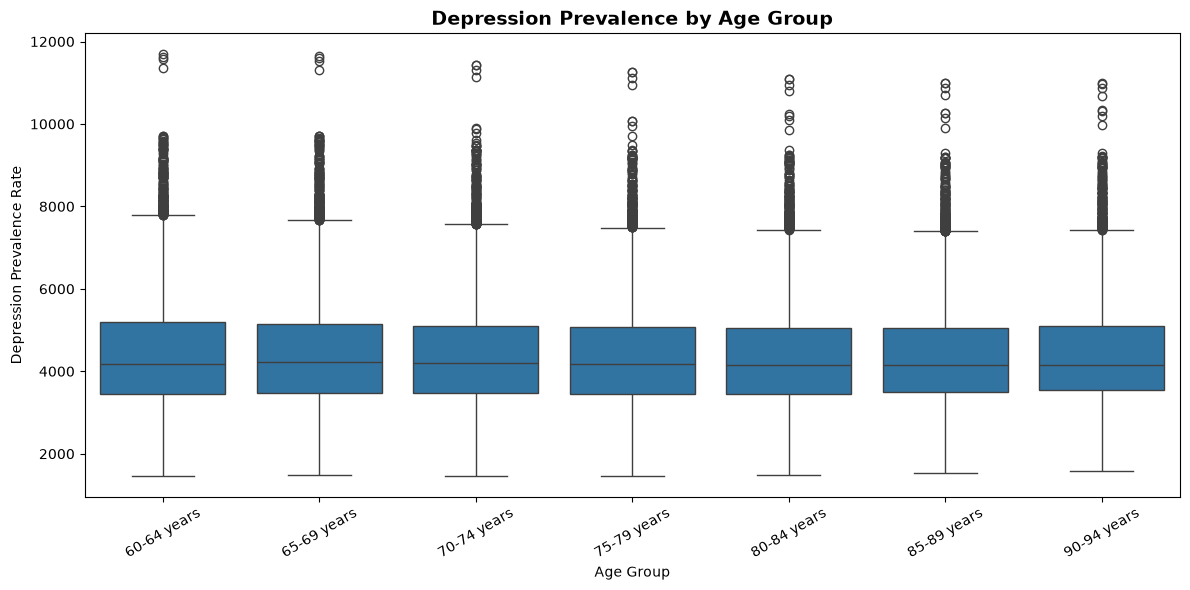

In [ ]:
import re

age_df = df.dropna(
    subset=["age_name", "val"]
).copy()

# Sort age groups by their starting age
age_order = sorted(
    age_df["age_name"].unique(),
    key=lambda x: int(re.search(r"\d+", x).group())
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=age_df,
    x="age_name",
    y="val",
    order=age_order,
    showfliers=True
)

plt.title(
    "Depression Prevalence by Age Group",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Age Group")
plt.ylabel("Depression Prevalence Rate")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
age_summary = (
    age_df.groupby("age_name")["val"]
    .agg(
        observations="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
    .reindex(age_order)
    .round(2)
)

display(age_summary)

,observations,mean,median,std,minimum,maximum
age_name,,,,,,
60-64 years,13872,4379.18,4184.32,1289.33,1466.93,11692.64
65-69 years,13872,4395.44,4224.45,1283.66,1476.00,11646.99
70-74 years,13872,4355.46,4193.68,1255.85,1470.04,11434.53
75-79 years,13872,4330.16,4166.27,1233.99,1470.65,11255.79
80-84 years,13872,4314.78,4148.50,1213.43,1477.59,11101.39
85-89 years,13872,4326.37,4146.91,1197.24,1523.47,11003.21
90-94 years,13872,4360.85,4163.72,1187.97,1591.25,10995.67


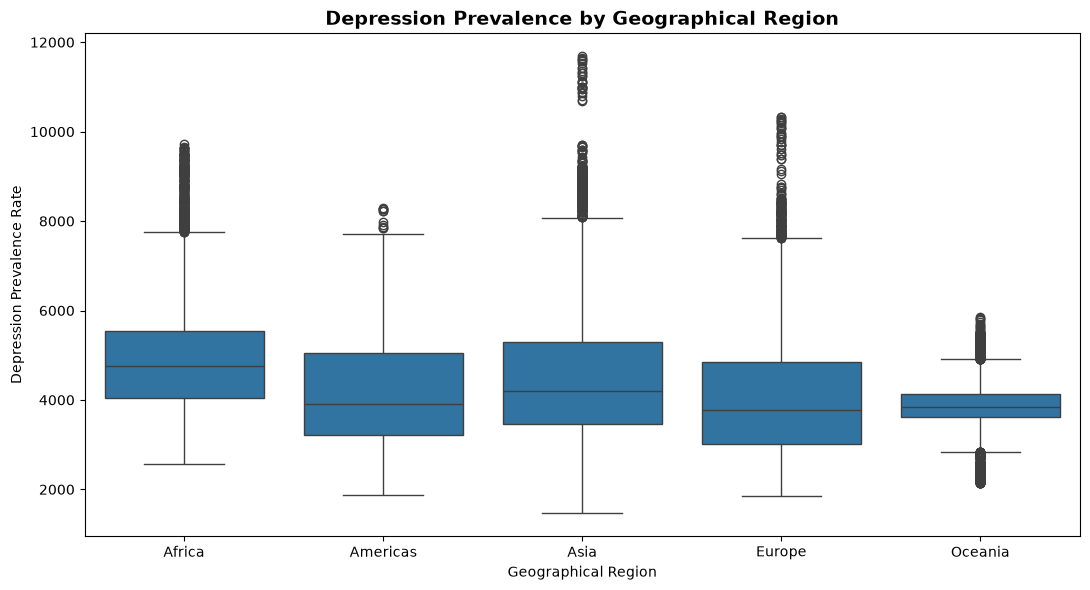

In [ ]:
region_order = [
    "Africa",
    "Americas",
    "Asia",
    "Europe",
    "Oceania"
]

region_df = df.dropna(
    subset=["geographical_region", "val"]
).copy()

region_df = region_df[
    region_df["geographical_region"].isin(region_order)
]

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=region_df,
    x="geographical_region",
    y="val",
    order=region_order,
    showfliers=True
)

plt.title(
    "Depression Prevalence by Geographical Region",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Geographical Region")
plt.ylabel("Depression Prevalence Rate")

plt.tight_layout()
plt.show()

In [ ]:
region_summary = (
    region_df.groupby("geographical_region")["val"]
    .agg(
        observations="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
    .reindex(region_order)
    .round(2)
)

display(region_summary)

,observations,mean,median,std,minimum,maximum
geographical_region,,,,,,
Africa,25704,4921.18,4763.53,1119.76,2573.06,9718.12
Americas,18564,4115.45,3917.47,1130.13,1877.15,8289.85
Asia,23324,4395.83,4188.97,1409.10,1466.93,11692.64
Europe,19992,4012.03,3765.44,1234.16,1845.30,10327.50
Oceania,9520,3880.48,3841.33,495.33,2134.28,5860.59


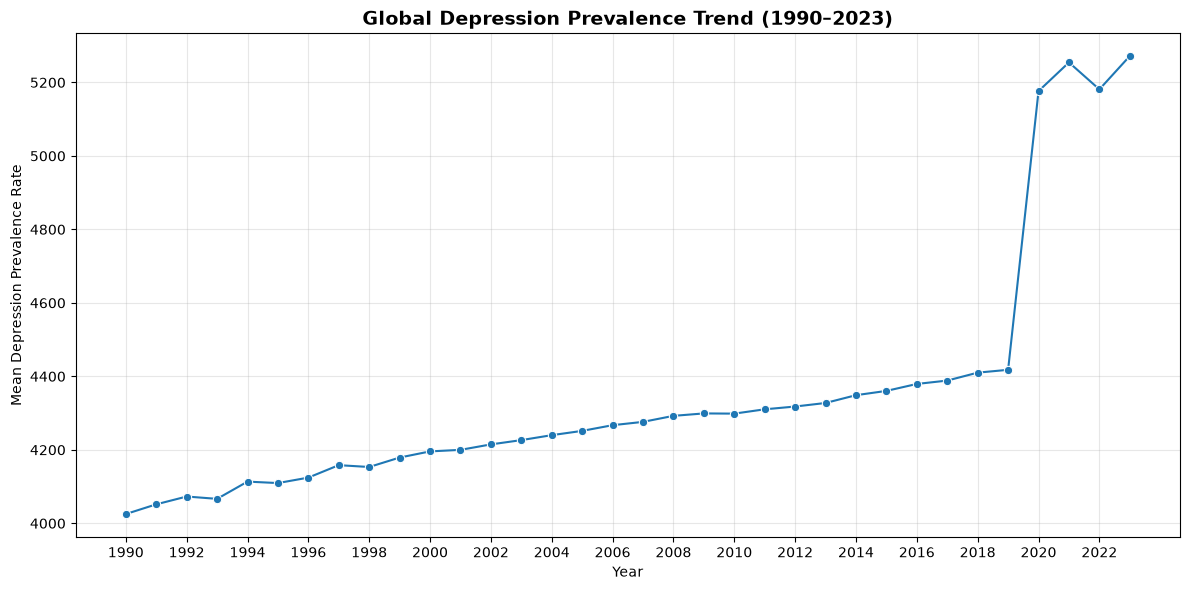

In [ ]:
trend_df = df.dropna(
    subset=["year", "val"]
).copy()

global_trend = (
    trend_df.groupby("year")["val"]
    .mean()
    .reset_index(name="mean_prevalence")
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=global_trend,
    x="year",
    y="mean_prevalence",
    marker="o"
)

plt.title(
    "Global Depression Prevalence Trend (1990–2023)",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Year")
plt.ylabel("Mean Depression Prevalence Rate")
plt.xticks(range(1990, 2024, 2))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
display(
    global_trend.round(2)
)

,year,mean_prevalence
0,1990,4025.19
1,1991,4051.61
2,1992,4072.86
3,1993,4066.52
4,1994,4113.46
5,1995,4109.50
6,1996,4124.37
7,1997,4158.24
8,1998,4153.24
9,1999,4178.95


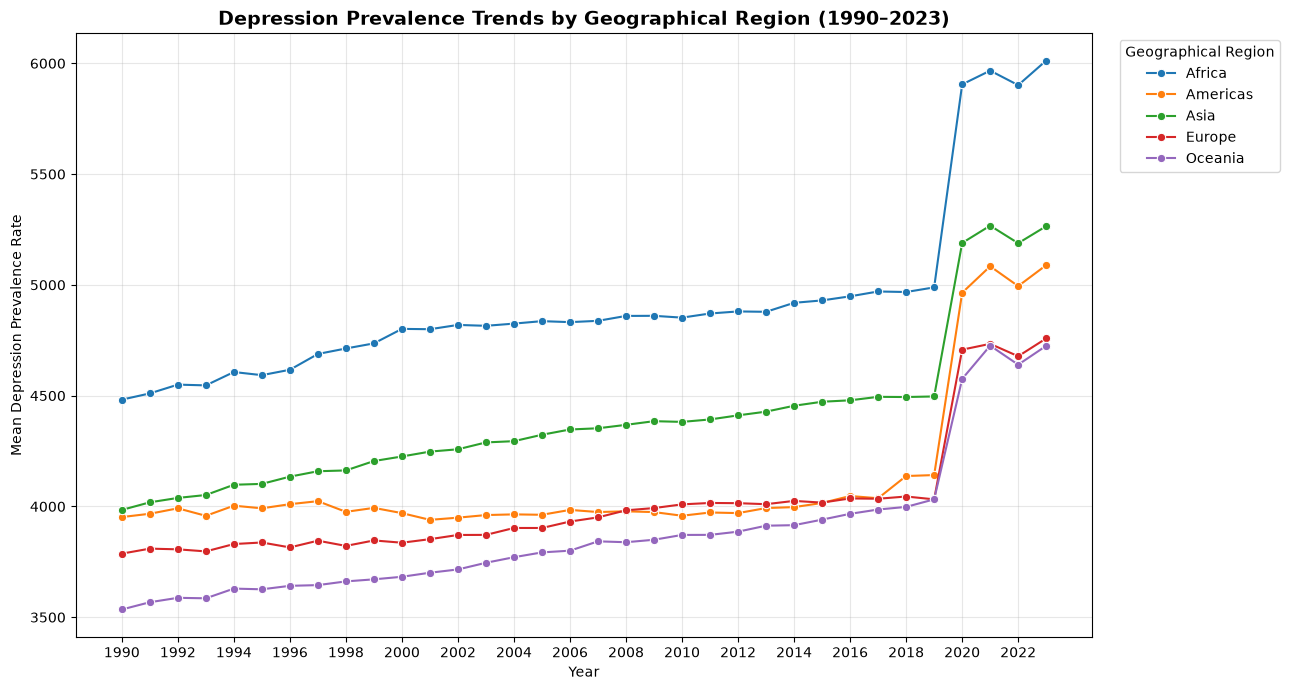

In [ ]:
regional_trend = (
    df.dropna(
        subset=["year", "val", "geographical_region"]
    )
    .groupby(
        ["year", "geographical_region"]
    )["val"]
    .mean()
    .reset_index(name="mean_prevalence")
)

plt.figure(figsize=(13, 7))

sns.lineplot(
    data=regional_trend,
    x="year",
    y="mean_prevalence",
    hue="geographical_region",
    hue_order=region_order,
    marker="o"
)

plt.title(
    "Depression Prevalence Trends by Geographical Region (1990–2023)",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Year")
plt.ylabel("Mean Depression Prevalence Rate")
plt.xticks(range(1990, 2024, 2))
plt.legend(
    title="Geographical Region",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
regional_trend_pivot = regional_trend.pivot(
    index="year",
    columns="geographical_region",
    values="mean_prevalence"
)

display(regional_trend_pivot.round(2))

geographical_region,Africa,Americas,Asia,Europe,Oceania
year,,,,,
1990,4482.04,3952.06,3984.23,3786.98,3534.87
1991,4510.15,3967.00,4018.63,3809.56,3567.66
1992,4549.78,3991.58,4038.44,3806.42,3587.58
1993,4546.42,3957.67,4051.59,3797.12,3585.41
1994,4606.65,4003.48,4097.88,3830.28,3629.20
1995,4592.53,3991.46,4101.80,3837.33,3625.98
1996,4616.89,4010.28,4134.50,3815.08,3641.70
1997,4688.21,4023.75,4158.90,3845.41,3644.92
1998,4712.91,3975.59,4162.52,3821.86,3661.68


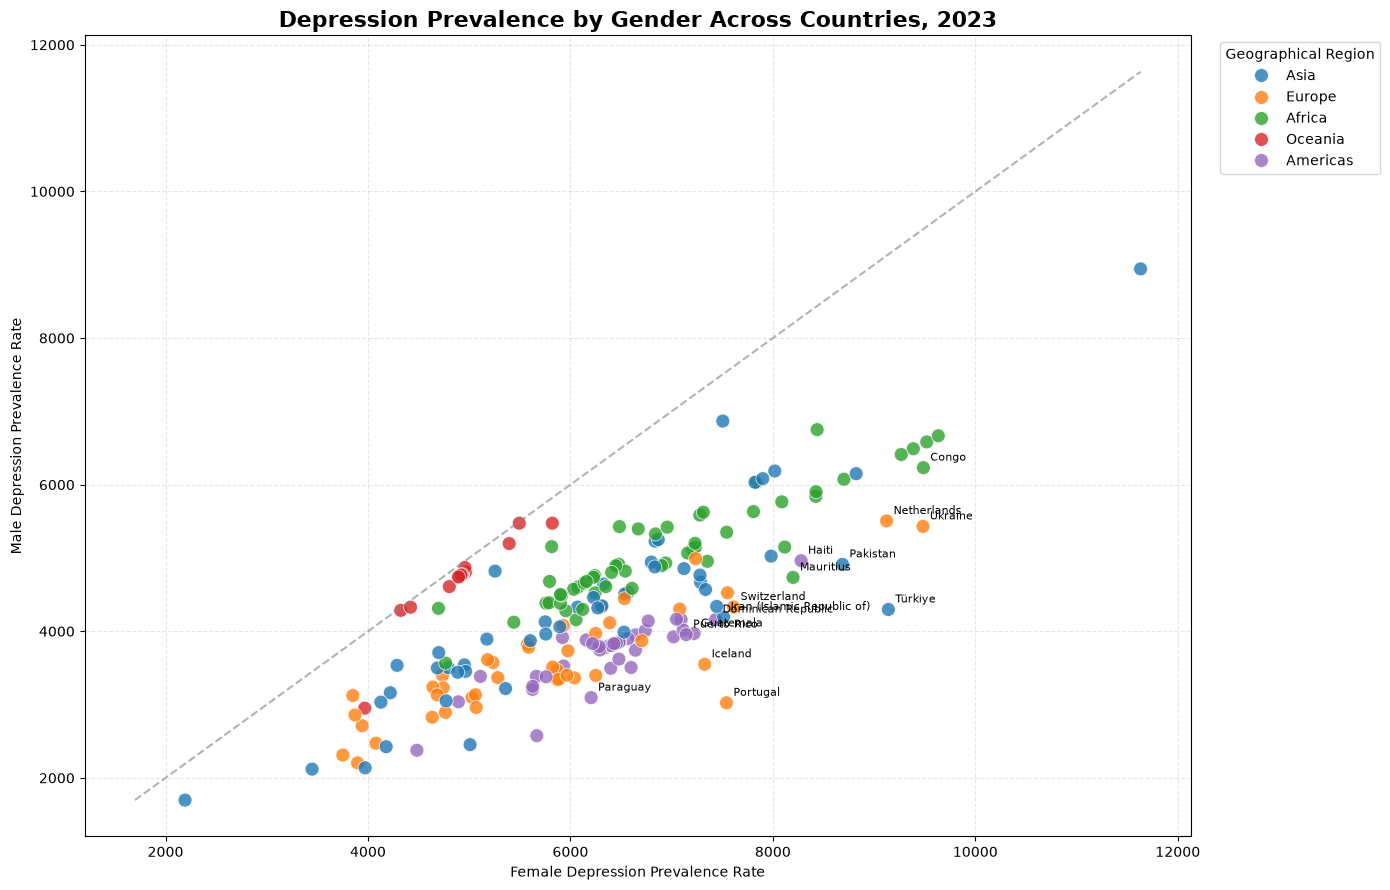

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select year and age group
plot_df = df[
    (df["year"] == 2023) &
    (df["age_name"] == "60-64 years") &
    (df["sex_name"].isin(["Female", "Male"]))
].copy()

# Pivot Female and Male values
scatter_df = (
    plot_df.pivot_table(
        index=["location_name", "geographical_region"],
        columns="sex_name",
        values="val"
    )
    .dropna(subset=["Female", "Male"])
    .reset_index()
)

# Create scatter plot
plt.figure(figsize=(14, 9))

sns.scatterplot(
    data=scatter_df,
    x="Female",
    y="Male",
    hue="geographical_region",
    s=100,
    alpha=0.8,
    edgecolor="white",
    linewidth=0.6
)

# Add equality reference line
min_val = min(
    scatter_df["Female"].min(),
    scatter_df["Male"].min()
)

max_val = max(
    scatter_df["Female"].max(),
    scatter_df["Male"].max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    color="grey",
    alpha=0.6
)

# Label selected countries
scatter_df["sex_difference"] = (
    scatter_df["Female"] - scatter_df["Male"]
).abs()

for _, row in scatter_df.nlargest(
    15, "sex_difference"
).iterrows():

    plt.annotate(
        row["location_name"],
        (row["Female"], row["Male"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.title(
    "Depression Prevalence by Gender Across Countries, 2023",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Female Depression Prevalence Rate")
plt.ylabel("Male Depression Prevalence Rate")

plt.legend(
    title="Geographical Region",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()